# Early-Career Developer Salary Prediction

**Mission:** To empower young people with the skills, guidance and opportunities to build successful careers.

**Use case:** A young developer (or their mentor) enters their country, experience, education, company size, work arrangement and role, and gets an estimated annual salary. They use it to negotiate fairly and to decide which skills and roles to aim for.

**Dataset:** Stack Overflow Annual Developer Survey 2025 (https://survey.stackoverflow.co/), 49,191 responses and 172 columns.

**Target:** `ConvertedCompYearly`, annual salary in USD, converted to thousands of USD (`salary_k`).

## 2: Load only the columns we need

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

TARGET_RAW = "ConvertedCompYearly"
FEATURES_NUM = ["WorkExp", "YearsCode"]
FEATURES_CAT = ["Country", "EdLevel", "OrgSize", "RemoteWork", "DevType", "ICorPM"]

use = ["Age", "Employment", TARGET_RAW] + FEATURES_NUM + FEATURES_CAT
raw = pd.read_csv("results.csv", usecols=use, encoding="utf-8-sig")
print(raw.shape)

(49191, 11)


## 3: Filter and clean 

In [20]:
df = raw.copy()
print("Start:", len(df))

df = df[(df["Employment"] == "Employed") &
        (df["Age"].isin(["18-24 years old", "25-34 years old"]))]
print("Employed and under 35:", len(df))

df = df[df[TARGET_RAW].between(5_000, 300_000)]
print("Salary between $5k and $300k:", len(df))

df = df.dropna(subset=FEATURES_NUM + FEATURES_CAT)
print("No missing features:", len(df))

df = df[(df["WorkExp"] <= 15) & (df["YearsCode"] <= 40)]
print("Experience in range:", len(df))

top_countries = df["Country"].value_counts().head(12).index
df = df[df["Country"].isin(top_countries)]
print("Top 12 countries:", len(df))

top_roles = df["DevType"].value_counts().head(9).index
df["DevType"] = df["DevType"].where(df["DevType"].isin(top_roles), "Other")

df["salary_k"] = df[TARGET_RAW] / 1000

# Columns used only for filtering are dropped
df = df.drop(columns=["Age", "Employment", TARGET_RAW]).reset_index(drop=True)

print("\nFinal shape:", df.shape)
df.head()

Start: 49191
Employed and under 35: 16914
Salary between $5k and $300k: 8376
No missing features: 8098
Experience in range: 8036
Top 12 countries: 5317

Final shape: (5317, 9)


,EdLevel,WorkExp,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Country,salary_k
0,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",8.0,14.0,"Developer, mobile",20 to 99 employees,People manager,Remote,Ukraine,61.256
1,"Associate degree (A.A., A.S., etc.)",2.0,10.0,"Developer, back-end",500 to 999 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibi...",Netherlands,104.413
2,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",9.0,15.0,Other,"5,000 to 9,999 employees",Individual contributor,Remote,Ukraine,70.000
3,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",7.0,10.0,"Developer, mobile",20 to 99 employees,Individual contributor,Remote,Ukraine,5.400
4,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",7.0,9.0,"Developer, back-end",100 to 499 employees,Individual contributor,Remote,Ukraine,65.691


## Simplify category labels

In [21]:
# Shorten category labels so the API and the app can use short, typeable values.
# Also merges "Other (please specify):" into "Other" and the two Hybrid options into "Hybrid".
LABELS = {
    "Country": {
        "United States of America": "USA",
        "United Kingdom of Great Britain and Northern Ireland": "UK",
    },
    "EdLevel": {
        "Primary/elementary school": "Primary",
        "Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)": "Secondary",
        "Some college/university study without earning a degree": "Some college",
        "Associate degree (A.A., A.S., etc.)": "Associate",
        "Bachelor’s degree (B.A., B.S., B.Eng., etc.)": "Bachelor",
        "Master’s degree (M.A., M.S., M.Eng., MBA, etc.)": "Master",
        "Professional degree (JD, MD, Ph.D, Ed.D, etc.)": "Professional",
        "Other (please specify):": "Other",
    },
    "OrgSize": {
        "Just me - I am a freelancer, sole proprietor, etc.": "Just me",
        "Less than 20 employees": "Under 20",
        "20 to 99 employees": "20-99",
        "100 to 499 employees": "100-499",
        "500 to 999 employees": "500-999",
        "1,000 to 4,999 employees": "1000-4999",
        "5,000 to 9,999 employees": "5000-9999",
        "10,000 or more employees": "10000+",
        "I don’t know": "Unknown",
    },
    "WorkArrangement": {
        "Hybrid (some remote, leans heavy to in-person)": "Hybrid",
        "Hybrid (some in-person, leans heavy to flexibility)": "Hybrid",
        "Your choice (very flexible, you can come in when you want or just as needed)": "Flexible",
    },
    "DevType": {
        "Developer, back-end": "Back-end",
        "Developer, front-end": "Front-end",
        "Developer, full-stack": "Full-stack",
        "Developer, mobile": "Mobile",
        "Developer, desktop or enterprise applications": "Desktop/Enterprise",
        "Developer, embedded applications or devices": "Embedded",
        "DevOps engineer or professional": "DevOps",
        "Architect, software or solutions": "Architect",
        "Other (please specify):": "Other",
    },
    "ICorPM": {"Individual contributor": "IC", "People manager": "Manager"},
}
# The survey calls this column RemoteWork, but it covers remote, hybrid, in-person and flexible.
df = df.rename(columns={"RemoteWork": "WorkArrangement"})
FEATURES_CAT = ["WorkArrangement" if c == "RemoteWork" else c for c in FEATURES_CAT]
for col, mapping in LABELS.items():
    df[col] = df[col].map(lambda v: mapping.get(v, v))

# Check: every category should now be short
for col in FEATURES_CAT:
    print(col, sorted(df[col].unique()))

Country ['Brazil', 'Canada', 'France', 'Germany', 'India', 'Italy', 'Netherlands', 'Poland', 'Spain', 'UK', 'USA', 'Ukraine']
EdLevel ['Associate', 'Bachelor', 'Master', 'Other', 'Primary', 'Professional', 'Secondary', 'Some college']
OrgSize ['100-499', '1000-4999', '10000+', '20-99', '500-999', '5000-9999', 'Just me', 'Under 20', 'Unknown']
WorkArrangement ['Flexible', 'Hybrid', 'In-person', 'Remote']
DevType ['Architect', 'Back-end', 'Desktop/Enterprise', 'DevOps', 'Embedded', 'Front-end', 'Full-stack', 'Mobile', 'Other']
ICorPM ['IC', 'Manager']


## 4: Correlation heatmap

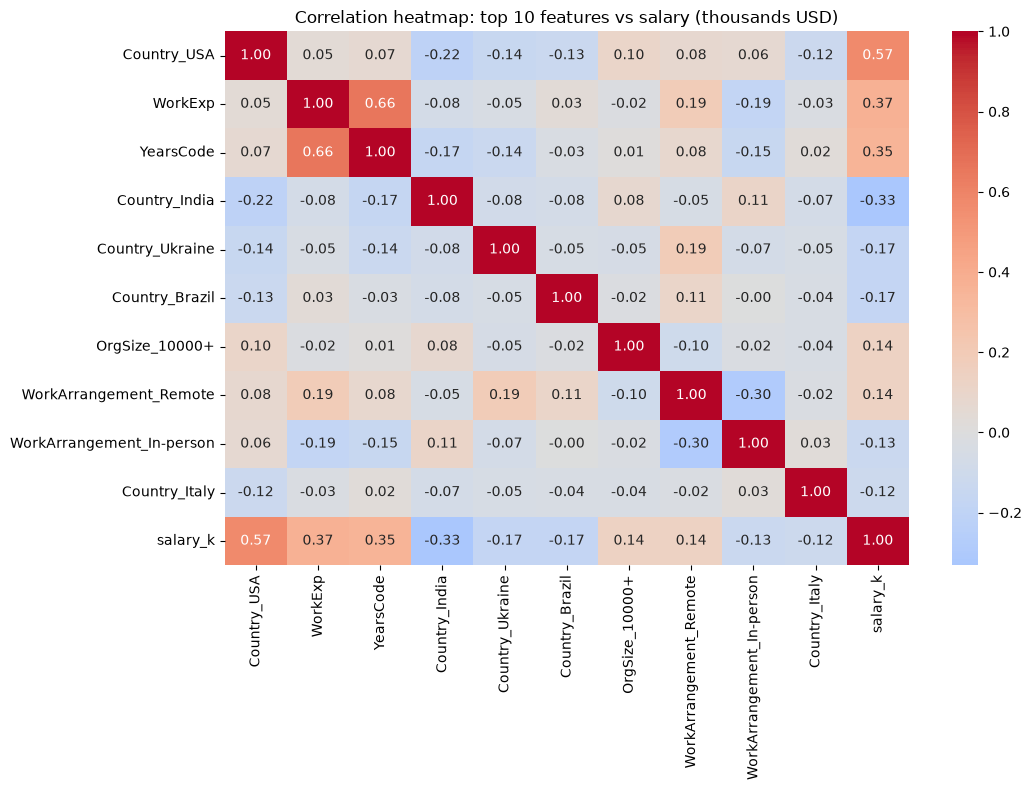

In [22]:
encoded = pd.get_dummies(df, columns=FEATURES_CAT, dtype=float)
corr_with_target = encoded.corr()["salary_k"].drop("salary_k")
top_cols = corr_with_target.abs().sort_values(ascending=False).head(10).index.tolist()

plt.figure(figsize=(11, 8))
sns.heatmap(encoded[top_cols + ["salary_k"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap: top 10 features vs salary (thousands USD)")
plt.tight_layout()
plt.show()

The heatmap shows that where a developer lives matters most for salary, especially being in the USA (higher) or India (lower), followed by years of experience. Company size and remote work have a much weaker link. WorkExp and YearsCode also move together, so I kept an eye on how that overlap affects the linear models. Because of this, I kept Country as a key feature and standardized the numeric columns.

## 5: Histograms of salary and experience

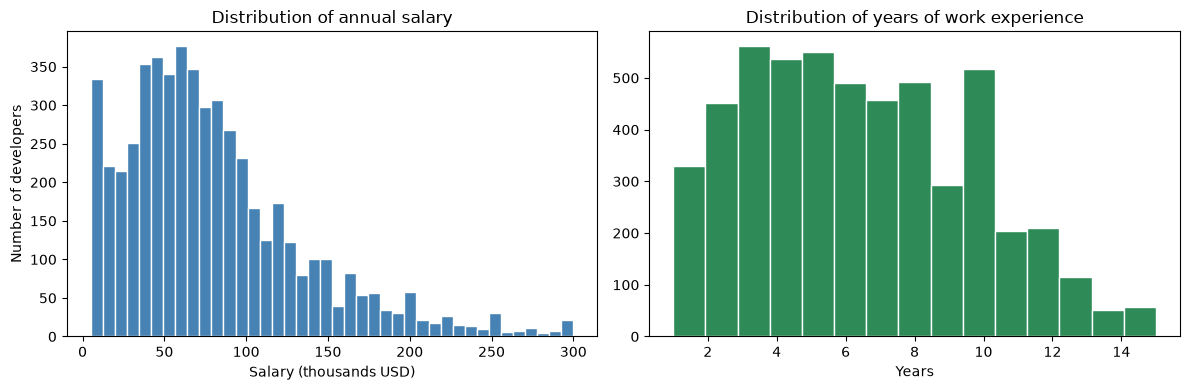

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["salary_k"], bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of annual salary")
axes[0].set_xlabel("Salary (thousands USD)")
axes[0].set_ylabel("Number of developers")
axes[1].hist(df["WorkExp"], bins=15, color="seagreen", edgecolor="white")
axes[1].set_title("Distribution of years of work experience")
axes[1].set_xlabel("Years")
plt.tight_layout()
plt.show()

Most developers in this dataset earn under about $100k, but a long tail of high earners stretches the salary distribution to the right. Because a few very high values can dominate the error, I capped salaries at $300k and used thousands of USD as the unit. I’ll also check whether the tree models handle this skew better than the linear ones.

## 6: Median salary by country

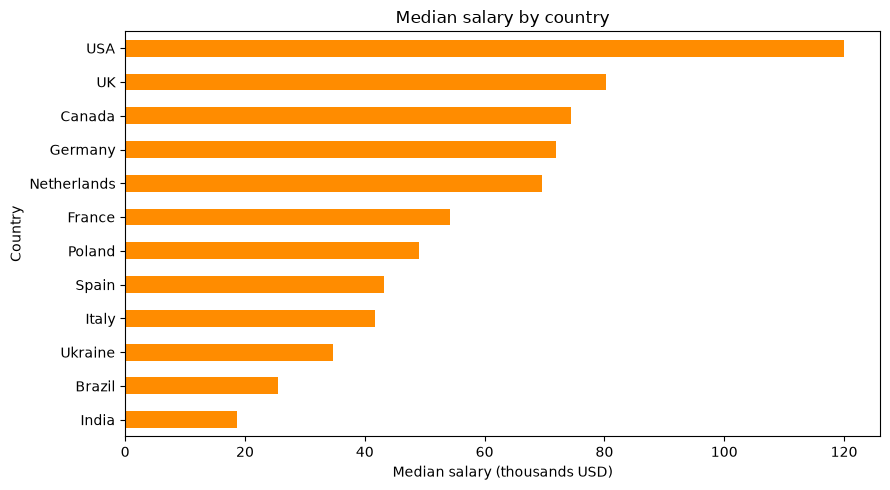

In [24]:
med = df.groupby("Country")["salary_k"].median().sort_values()
med.index = med.index.str.replace(" of Great Britain and Northern Ireland", "", regex=False)
med.plot(kind="barh", figsize=(9, 5), color="darkorange")
plt.xlabel("Median salary (thousands USD)")
plt.title("Median salary by country")
plt.tight_layout()
plt.show()

Pay differs enormously between countries: the median in the USA is roughly six times the median in India. A single number can’t capture that gap, so I one-hot encoded Country. I only kept the 12 countries with enough responses, so the model has enough examples to learn from each one.

## Feature engineering

**Dropped columns and why**
- 160+ survey columns (AI tool questions, technology preferences, job satisfaction, etc.): not available to a young developer when asking "what should I earn?", and many are mostly empty.
- `Age` and `Employment`: used only to keep early-career employed people, so they carry no extra information after filtering.
- `ConvertedCompYearly`: replaced by `salary_k` (the same value in thousands of USD).

**Features kept (8):** `Country`, `WorkExp`, `YearsCode`, `EdLevel`, `OrgSize`, `RemoteWork`, `DevType`, `ICorPM`.

**Which features matter most:** from the heatmap, Country and experience. This will be confirmed with the random forest's feature importances after training.

## Split, encode, scale

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

X = df[FEATURES_NUM + FEATURES_CAT]
y = df["salary_k"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Categorical -> 0/1 columns; numeric -> standardized. Both are fitted on TRAIN only.
preprocess = ColumnTransformer([
    ("num", StandardScaler(), FEATURES_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEATURES_CAT),
])
X_train_p = preprocess.fit_transform(X_train)   # fit on train
X_test_p = preprocess.transform(X_test)         # only transform on test

print("Train:", X_train_p.shape, "Test:", X_test_p.shape)

Train: (4253, 46) Test: (1064, 46)


## Tune SGDRegressor (learning rate, regularization, epochs)

In [26]:
def run_sgd(eta0, alpha, epochs, A, yA, B, yB):
    """Train with partial_fit and record MSE on A and B after every epoch."""
    model = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha,
                         penalty="l2", random_state=42)
    a_loss, b_loss = [], []
    for _ in range(epochs):
        model.partial_fit(A, yA)
        a_loss.append(mean_squared_error(yA, model.predict(A)))
        b_loss.append(mean_squared_error(yB, model.predict(B)))
    return model, a_loss, b_loss

# Tune on a validation split taken from the TRAINING data, so test stays untouched
X_a, X_val, y_a, y_val = train_test_split(X_train_p, y_train, test_size=0.2, random_state=0)

rows = []
for eta0 in [0.0001, 0.001, 0.01, 0.05]:        # learning rate
    for alpha in [1e-5, 1e-3, 1e-1, 1]:          # regularization strength
        for epochs in [10, 50, 100]:             # number of epochs
            _, tr, va = run_sgd(eta0, alpha, epochs, X_a, y_a, X_val, y_val)
            rows.append({"eta0": eta0, "alpha": alpha, "epochs": epochs,
                         "train_mse": tr[-1], "val_mse": va[-1]})

tuning = pd.DataFrame(rows).sort_values("val_mse").reset_index(drop=True)
print(tuning.head(8).to_string(float_format=lambda v: f"{v:.5g}"))
print("\nWorst:")
print(tuning.tail(4).to_string(float_format=lambda v: f"{v:.5g}"))

   eta0  alpha  epochs  train_mse  val_mse
0 0.001  1e-05      50     1220.1   1342.1
1 0.001  0.001      50     1220.6   1342.4
2 0.001  0.001     100     1219.7     1343
3 0.001  1e-05     100     1219.2     1343
4  0.01  1e-05      10     1239.1   1349.4
5  0.01  0.001      10       1240   1350.3
6  0.01  0.001     100     1239.9   1350.9
7  0.01  1e-05      50     1239.4   1350.9

Worst:
    eta0  alpha  epochs  train_mse  val_mse
44  0.01      1      50       2315   2457.4
45  0.05      1      10     2361.3   2519.9
46  0.05      1      50     2361.3   2519.9
47  0.05      1     100     2361.3   2519.9


## Final SGD and the loss curve

Best settings: {'eta0': np.float64(0.001), 'alpha': np.float64(1e-05), 'epochs': np.float64(50.0)}


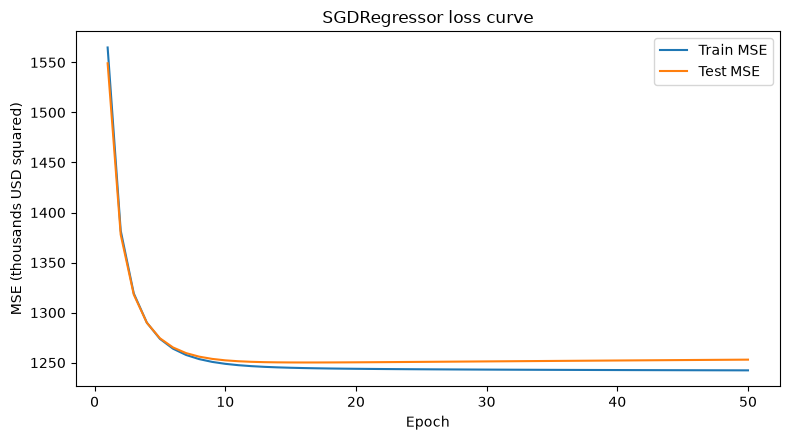

In [27]:
best = tuning.iloc[0]
print("Best settings:", dict(best[["eta0", "alpha", "epochs"]]))

sgd, train_curve, test_curve = run_sgd(best["eta0"], best["alpha"], int(best["epochs"]),
                                       X_train_p, y_train, X_test_p, y_test)

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(train_curve) + 1), train_curve, label="Train MSE")
plt.plot(range(1, len(test_curve) + 1), test_curve, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (thousands USD squared)")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.tight_layout()
plt.show()

## The other three models

In [28]:
lin = LinearRegression().fit(X_train_p, y_train)
tree = DecisionTreeRegressor(min_samples_leaf=30, random_state=42).fit(X_train_p, y_train)
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                               random_state=42, n_jobs=-1).fit(X_train_p, y_train)

## Comparison table and best model

In [29]:
models = {"SGDRegressor": sgd, "LinearRegression": lin,
          "DecisionTree": tree, "RandomForest": forest}

results = pd.DataFrame([{
    "Model": name,
    "Train MSE": mean_squared_error(y_train, m.predict(X_train_p)),
    "Test MSE": mean_squared_error(y_test, m.predict(X_test_p)),
} for name, m in models.items()]).set_index("Model")
results["Test RMSE ($k)"] = results["Test MSE"] ** 0.5

baseline = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(results.round(1))
print(f"\nBaseline (always predict the mean salary): test MSE = {baseline:.1f}")

best_name = results["Test MSE"].idxmin()
print(f"\nBEST MODEL (lowest test MSE): {best_name}")

                  Train MSE  Test MSE  Test RMSE ($k)
Model                                                
SGDRegressor         1242.3    1253.0            35.4
LinearRegression     1239.3    1256.9            35.5
DecisionTree         1186.0    1362.4            36.9
RandomForest          798.1    1273.3            35.7

Baseline (always predict the mean salary): test MSE = 2891.8

BEST MODEL (lowest test MSE): SGDRegressor


## Which features matter most (random forest)

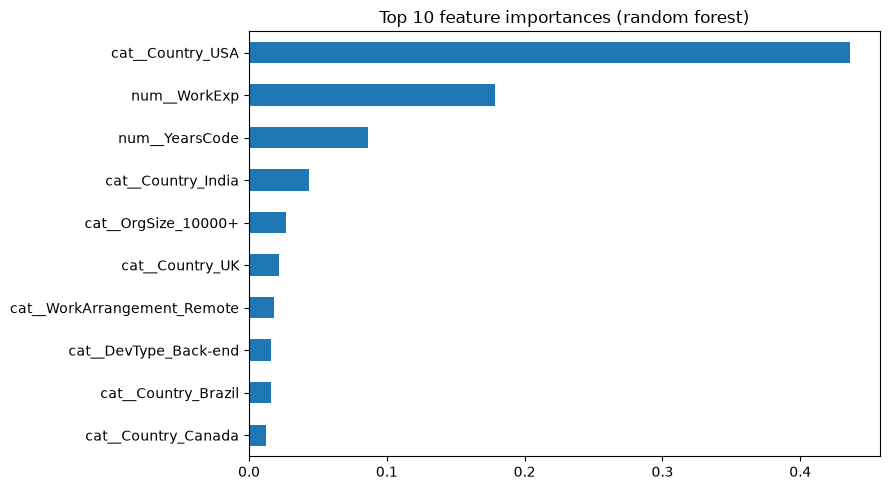

In [30]:
imp = pd.Series(forest.feature_importances_,
                index=preprocess.get_feature_names_out()).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 feature importances (random forest)")
plt.tight_layout()
plt.show()

## Scatter before and after

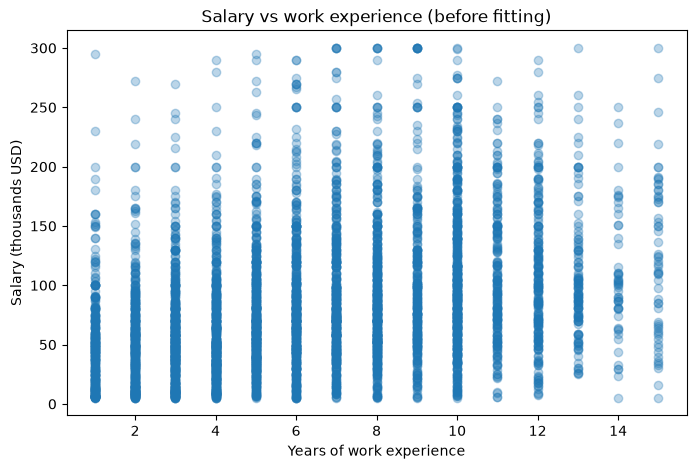

In [31]:
# Before
plt.figure(figsize=(8, 5))
plt.scatter(df["WorkExp"], df["salary_k"], alpha=0.3)
plt.xlabel("Years of work experience")
plt.ylabel("Salary (thousands USD)")
plt.title("Salary vs work experience (before fitting)")
plt.show()

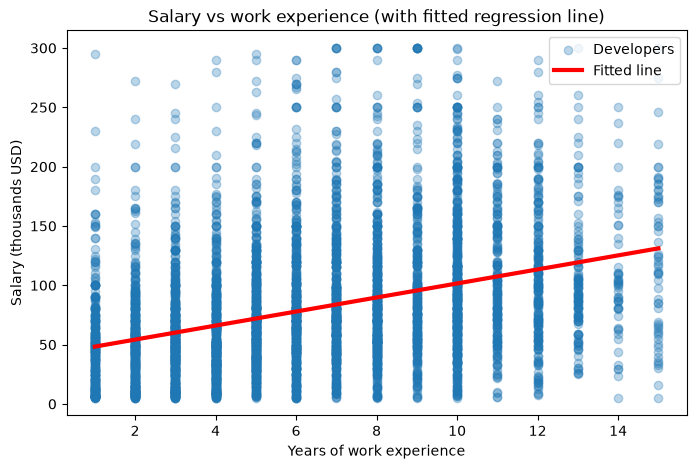

In [32]:
# After: one-feature linear regression, for this plot only
one = LinearRegression().fit(df[["WorkExp"]], df["salary_k"])
xs = pd.DataFrame({"WorkExp": np.linspace(df["WorkExp"].min(), df["WorkExp"].max(), 100)})

plt.figure(figsize=(8, 5))
plt.scatter(df["WorkExp"], df["salary_k"], alpha=0.3, label="Developers")
plt.plot(xs["WorkExp"], one.predict(xs), color="red", linewidth=3, label="Fitted line")
plt.xlabel("Years of work experience")
plt.ylabel("Salary (thousands USD)")
plt.title("Salary vs work experience (with fitted regression line)")
plt.legend()
plt.show()

## Save the best model and predict one row

In [33]:
import joblib
import os
from sklearn.pipeline import Pipeline

# The best model is chosen by lowest test MSE (best_name came from the comparison table)
best_model = models[best_name]

# Bundle preprocessing + model, so the API only needs one object
best_pipeline = Pipeline([("preprocess", preprocess), ("model", best_model)])

os.makedirs("../API", exist_ok=True)
joblib.dump(best_pipeline, "../API/best_model.pkl")

# Sanity check: the reloaded file must give the same test MSE
reloaded = joblib.load("../API/best_model.pkl")
print("Saved:", best_name)
print("Test MSE after reload:", round(mean_squared_error(y_test, reloaded.predict(X_test)), 1))

Saved: SGDRegressor
Test MSE after reload: 1253.0


In [34]:
def predict_one(row, model_path="../API/best_model.pkl"):
    """Load the saved pipeline and predict salary (thousands USD) for ONE row."""
    model = joblib.load(model_path)
    return float(model.predict(row)[0])

# Try it on the first row of the test set
one_row = X_test.iloc[[0]]          # double brackets keep it as a 1-row table
print(one_row.T)
print("\nPredicted salary ($k):", round(predict_one(one_row), 1))
print("Actual salary ($k):   ", round(y_test.iloc[0], 1))

                       230
WorkExp                3.0
YearsCode             10.0
Country             Canada
EdLevel           Bachelor
OrgSize           Under 20
WorkArrangement     Remote
DevType          Front-end
ICorPM                  IC

Predicted salary ($k): 71.3
Actual salary ($k):    65.7


## Print the allowed values for the API

In [35]:
for col in FEATURES_CAT:
    print(col, sorted(df[col].unique()))
print(df[FEATURES_NUM].agg(["min", "max"]))

Country ['Brazil', 'Canada', 'France', 'Germany', 'India', 'Italy', 'Netherlands', 'Poland', 'Spain', 'UK', 'USA', 'Ukraine']
EdLevel ['Associate', 'Bachelor', 'Master', 'Other', 'Primary', 'Professional', 'Secondary', 'Some college']
OrgSize ['100-499', '1000-4999', '10000+', '20-99', '500-999', '5000-9999', 'Just me', 'Under 20', 'Unknown']
WorkArrangement ['Flexible', 'Hybrid', 'In-person', 'Remote']
DevType ['Architect', 'Back-end', 'Desktop/Enterprise', 'DevOps', 'Embedded', 'Front-end', 'Full-stack', 'Mobile', 'Other']
ICorPM ['IC', 'Manager']
     WorkExp  YearsCode
min      1.0        1.0
max     15.0       27.0


**Loss curve: what it shows and what I decided**

Train and test loss both fall fast in the first 10 epochs (test MSE from about 1549 to 1252) and then stay flat, almost on top of each other, so the model is not overfitting. Training longer adds nothing, so I kept 50 epochs as a safe setting.

**Tuning: what changed the loss**

A learning rate of 0.001 gave the lowest validation loss (1342), while 0.0001 was slower (1353) and 0.05 was much worse (1506). Strong regularization hurt most: alpha = 1 raised the loss to 2353 because the model underfit, while small alpha values gave almost the same loss as each other. More than 10 epochs helped a little (1349 to 1342), and 50 and 100 epochs gave the same result.

**Scatter plots: what they show and what I decided**

Salary rises with experience, by about $5.9k per year according to the fitted line. The points are widely spread around the line (correlation 0.37), so experience alone explains little, and I kept all eight features in the final model.

In [36]:
# Rows for demonstrating /retrain: same columns as the training data, plus the salary
sample = X_test.assign(salary_k=y_test).head(100)
sample.to_csv("sample_retrain.csv", index=False)
print(sample.shape)
sample.head(3)

(100, 9)


,WorkExp,YearsCode,Country,EdLevel,OrgSize,WorkArrangement,DevType,ICorPM,salary_k
230,3.0,10.0,Canada,Bachelor,Under 20,Remote,Front-end,IC,65.663
2093,5.0,11.0,Ukraine,Bachelor,20-99,Remote,Other,IC,48.000
3749,4.0,4.0,UK,Some college,500-999,Flexible,Full-stack,IC,76.239
